## Programa para Adquirir Dados

In [1]:
import time
import clr
import numpy as np
import time 
from pylablib.devices import Thorlabs
from structured_optics import *
from structured_optics.hologram import slm_hologram
from structured_optics.slmdisplay import My_SLM
from tqdm import tqdm
from camera import *
from utils import *
import h5py
from pathlib import Path

# Add References to .NET libraries

clr.AddReference("C:\\Program Files\\Thorlabs\\Kinesis\\Thorlabs.MotionControl.DeviceManagerCLI.dll")
clr.AddReference("C:\\Program Files\\Thorlabs\\Kinesis\\Thorlabs.MotionControl.GenericMotorCLI.dll")
clr.AddReference("C:\\Program Files\\Thorlabs\\Kinesis\\ThorLabs.MotionControl.KCube.StepperMotorCLI.dll")
from Thorlabs.MotionControl.DeviceManagerCLI import *
from Thorlabs.MotionControl.GenericMotorCLI import *
from Thorlabs.MotionControl.KCube.StepperMotorCLI import *
from System import Decimal  # necessary for real world units


## Funções

In [2]:
def calculate_fix_std_LG(p, l):
    N = 2*p + abs(l) + 1
    A = C**2 / N                       # target w(z)^2
    disc = 1 - 16*z**2/(k**2 * A**2)
    if disc < 0:
        print(f"mode ({p},{l}) impossible: need A >= 4z/k")
        return None
    W2 = (A/2)*(1 + np.sqrt(disc))     # waist^2 at the SLM image plane
    W = np.sqrt(W2)
    return W/mu                  # waist on the SLM

def calculate_fix_std_HG(n):
    N = 2*n + 1
    A = C**2 / N                       # target w(z)^2
    disc = 1 - 16*z**2/(k**2 * A**2)
    if disc < 0:
        print(f"mode ({n},{0}) impossible: need A >= 4z/k")
        return None
    W2 = (A/2)*(1 + np.sqrt(disc))     # waist^2 at the SLM image plane
    W = np.sqrt(W2)
    return W/mu 

## Parâmetros

In [ ]:
FOLDER = 'Amostras_10_2026/'


#parametros laser e slm
pixel_size = 8e-6  #tamanho do pixel do slm 
lamb = 633e-9   #comprimento de onda
waist = 0.3e-3  #cintura do feixe que sai do slm
x_grating = 3  #grating do slm em x
y_grating = 4  #grating do slm em y

#parametros lentes e propagação
mu = 0.6930012799317185/0.5 #parâmetro de magnificação devido ao sistema 4F após o SLM
z = 0 #Distância entre o waist pós 4F e a amostra, utilizado para calcular fix std
C = 0.65e-3#0.5e-3  #std a ser fixado
ANGLE = -4.5*np.pi/180 #Resumo: feixe passa por periscópio, ele fica torto de lado, esse ângulo resolve.


#parametros motor de passo
resolution = 50  #Resolução dos motores de passo
step_size = 200e-9 #tamanho do passo dos motores de passo
NUM_REP = 5  #numero de repetições da medida
z_start = 0.004  #inicio motor de passo

#parametros camera
EXPO = 1/10#1/9091   #exposição camera em segundos
BIT = 8     #bitdepth da camera
pixel_cam = 3.75e-6 #tamanho do pixel da camera
width_cam = 1280 #largura da camera
height_cam = 960 #altura da camera
NUM_BACK = 5 #numero de imagens para calcular o background
ZCAM_CM = 20  #distancia amostra camera


#parametros amostra
AMOSTRA = "Latao"   #tipo de amostra
ANGULO_AMOSTRA = 90 #angulo das ranhuras. 90 representa vertical, 45 diagonal e 0 horizontal.



In [4]:
"""folder = Path(FOLDER)
folder.mkdir(exist_ok=True)""" #cria a pasta onde salvamos os dados, só precisa ser rodado uma vez, por isso está comentado.

'folder = Path(FOLDER)\nfolder.mkdir(exist_ok=True)'

## Primeiro alinhamento e check de equipamentos

In [5]:
#Inicializa e set home dos motores de passo

stage_z = Thorlabs.kinesis.KinesisMotor('26005619',scale='ZST',  default_channel=2, is_rack_system=False)
print(f" stage z  -- {stage_z.get_position(scale= 'ZST')}")
stages = [stage_z]

for _ in stages:
    print(_.is_homed())
    if _.is_homed() == False:
        _.home()
for _ in stages:
    _.wait_for_home()


 stage z  -- 0.004009799876944944
True


c:\Users\Altilano\Documents\python\Speckle\.venv\Lib\site-packages\pylablib\devices\Thorlabs\kinesis.py:235: UserWarning: model number KST201 doesn't match the device ID prefix 26(KST101)
  warnings.warn("model number {} doesn't match the device ID prefix {}({})".format(model_no,port,port_model_no))


In [6]:
#inicializa camera, slm e lista de modos a serem medidos (até ordem 5)

slm = My_SLM(1)
width = slm.width
height = slm.height

print(width, height)

cam = init_camera(bitdepth=BIT, exposure_s = EXPO)
take_picture(cam)               # discard possible stale frame
frame = take_picture(cam)


hg_modes = [[0,0], [0,1], [1,0], [2,0], [1,1], [0,2], [3,0], 
            [2,1], [1,2], [0,3], [4,0], [3,1], [2,2], [1,3], 
            [0,4], [5,0], [4,1], [3,2], [2,3], [1,4], [0,5]]
lg_modes = [[0,0], [0,1], [0,-1], [0,2], [1,0], [0,-2], [0,3], 
            [1,1], [1,-1], [0,-3], [0,4], [1, 2], [1,-2], [2, 0], 
            [0,-4], [0,5], [1,3], [1, -3], [2, 1], [2,-1], [0,-5]]

1920 1080


In [7]:
#inicializa objeto beam que contém os parâmetros do feixe gerado

width = slm.width
height = slm.height

beam = Beam(nix = pixel_size*width/2, Dx = width,
            niy = pixel_size*height/2, Dy = height,
            waist = waist, lamb = lamb)

k = beam.k()

In [8]:
#Define qual o campo do objeto beam, gera um holograma a partir desse campo e atualiza a máscara do slm com esse holograma

beam.lg(2,2, angle=ANGLE)
#beam.triangle() #usado para encontrar o plano do slm, visto que um triângulo difrata muito rápido
holo = slm_hologram(beam, x_grating, y_grating)
slm.update_image(holo)

## Dados LG waist normal

In [9]:
beam.waist = waist

with h5py.File(f"{FOLDER}data_LG_amostra{AMOSTRA}_orientacao{ANGULO_AMOSTRA}.h5", "w") as file:
    file.attrs.update({
        'expo': f"{EXPO}s",
        'bit_depth': BIT,
        'step_size_nm': int(round(step_size * 1e9)),
        'cam_pixel_size_um': pixel_cam * 1e6,
        'amostra': str(AMOSTRA),
        'angulo_amostra_deg': ANGULO_AMOSTRA,
        'magnification': mu,
        'waist': waist,
        'z': z,
        'lamb': lamb,
        "zcam_cm": ZCAM_CM,
    })

    slm.update_image(np.zeros((height, width), dtype='uint8'))
    time.sleep(0.2)
    background = file.create_dataset("background", (NUM_BACK, height_cam, width_cam), dtype='uint8')
    for i in range(NUM_BACK):
        background[i] = take_picture(cam)
        time.sleep(EXPO)

    for mode in tqdm(lg_modes, desc="Processing LG modes"):

        l = mode[1]
        p = mode[0]
        mode_group = file.create_group(f"LG_p{p}l{l}")
        images_ds = mode_group.create_dataset("images", (NUM_REP, resolution,height_cam, width_cam), dtype='uint8')

        beam.lg(l,p, angle=ANGLE)
        holo = slm_hologram(beam, x_grating, y_grating)
        slm.update_image(holo)
        time.sleep(EXPO)
        for rep in range(NUM_REP):
            stage_z.move_to(z_start-0.001) # in meter
            stage_z.wait_move()
            stage_z.move_to(z_start) # in meter
            stage_z.wait_move()
            for i in range(resolution):
                stage_z.move_to(z_start + i*step_size)
                stage_z.wait_move()
                time.sleep(EXPO)
                img = take_picture(cam)
                images_ds[rep, i] = img
            file.flush()


Processing LG modes: 100%|██████████| 21/21 [25:08<00:00, 71.82s/it]


## Dados HG waist normal

In [10]:
beam.waist = waist

with h5py.File(f"{FOLDER}data_HG_amostra{AMOSTRA}_orientacao{ANGULO_AMOSTRA}.h5", "w") as file:
    file.attrs.update({
        'expo': f"{EXPO}s",
        'bit_depth': BIT,
        'step_size_nm': int(round(step_size * 1e9)),
        'cam_pixel_size_um': pixel_cam * 1e6,
        'amostra': str(AMOSTRA),
        'angulo_amostra_deg': ANGULO_AMOSTRA,
        'magnification': mu,
        'waist': waist,
        'z': z,
        'lamb': lamb,
        "zcam_cm": ZCAM_CM,
    })
    
    slm.update_image(np.zeros((height, width), dtype='uint8'))
    time.sleep(0.2)
    background = file.create_dataset("background", (NUM_BACK, height_cam, width_cam), dtype='uint8')
    for i in range(NUM_BACK):
        background[i] = take_picture(cam)
        time.sleep(EXPO)


    for n in tqdm(range(6), desc="Processing HG modes"):
        mode_group = file.create_group(f"HG_n{n}m{0}")
        images_ds = mode_group.create_dataset("images", (NUM_REP, resolution,height_cam, width_cam), dtype='uint8')

        beam.hg(n,0, angle=ANGLE)
        holo = slm_hologram(beam, x_grating, y_grating)
        slm.update_image(holo)
        time.sleep(EXPO)
        for rep in range(NUM_REP):
            stage_z.move_to(z_start-0.001) # in meter
            stage_z.wait_move()
            stage_z.move_to(z_start) # in meter
            stage_z.wait_move()
            for i in range(resolution):
                stage_z.move_to(z_start + i*step_size)
                stage_z.wait_move()
                time.sleep(EXPO)
                img = take_picture(cam)
                images_ds[rep, i] = img
            file.flush()

Processing HG modes: 100%|██████████| 6/6 [07:11<00:00, 71.92s/it]


## Dados LG std fixo

In [11]:

with h5py.File(f"{FOLDER}data_LG_fix_amostra{AMOSTRA}_orientacao{ANGULO_AMOSTRA}.h5", "w") as file:
    file.attrs.update({
        'expo': f"{EXPO}s",
        'bit_depth': BIT,
        'step_size_nm': int(round(step_size * 1e9)),
        'cam_pixel_size_um': pixel_cam * 1e6,
        'amostra': str(AMOSTRA),
        'angulo_amostra_deg': ANGULO_AMOSTRA,
        'magnification': mu,
        'waist': waist,
        'z': z,
        'lamb': lamb,
        "zcam_cm": ZCAM_CM,
        'C': C
    })

    slm.update_image(np.zeros((height, width), dtype='uint8'))
    time.sleep(0.2)
    background = file.create_dataset("background", (NUM_BACK, height_cam, width_cam), dtype='uint8')
    for i in range(NUM_BACK):
        background[i] = take_picture(cam)
        time.sleep(EXPO)


    for mode in tqdm(lg_modes, desc="Processing LG fix std modes"):

        l = mode[1]
        p = mode[0]
        mode_group = file.create_group(f"LG_p{p}l{l}")
        images_ds = mode_group.create_dataset("images", (NUM_REP, resolution,height_cam, width_cam), dtype='uint8')

        beam.waist = calculate_fix_std_LG(p,l)
        beam.lg(l,p, angle=ANGLE)
        holo = slm_hologram(beam, x_grating, y_grating)
        slm.update_image(holo)
        time.sleep(EXPO)
        for rep in range(NUM_REP):
            stage_z.move_to(z_start-0.001) # in meter
            stage_z.wait_move()
            stage_z.move_to(z_start) # in meter
            stage_z.wait_move()
            for i in range(resolution):
                stage_z.move_to(z_start + i*step_size)
                stage_z.wait_move()
                time.sleep(EXPO)
                img = take_picture(cam)
                images_ds[rep, i] = img
            file.flush()

Processing LG fix std modes: 100%|██████████| 21/21 [25:07<00:00, 71.80s/it]


## Dados HG std fixo

In [12]:

with h5py.File(f"{FOLDER}data_HG_fix_amostra{AMOSTRA}_orientacao{ANGULO_AMOSTRA}.h5", "w") as file:
    file.attrs.update({
        'expo': f"{EXPO}s",
        'bit_depth': BIT,
        'step_size_nm': int(round(step_size * 1e9)),
        'cam_pixel_size_um': pixel_cam * 1e6,
        'amostra': str(AMOSTRA),
        'angulo_amostra_deg': ANGULO_AMOSTRA,
        'magnification': mu,
        'waist': waist,
        'z': z,
        'lamb': lamb,
        "zcam_cm": ZCAM_CM,
        'C': C
    })

    slm.update_image(np.zeros((height, width), dtype='uint8'))
    time.sleep(0.2)
    background = file.create_dataset("background", (NUM_BACK, height_cam, width_cam), dtype='uint8')
    for i in range(NUM_BACK):
        background[i] = take_picture(cam)
        time.sleep(EXPO)

    for n in tqdm(range(6), desc="Processing HG fix std modes"):
        mode_group = file.create_group(f"HG_n{n}m{0}")
        images_ds = mode_group.create_dataset("images", (NUM_REP, resolution,height_cam, width_cam), dtype='uint8')

        beam.waist = calculate_fix_std_HG(n)
        beam.hg(n,0, angle=ANGLE)
        holo = slm_hologram(beam, x_grating, y_grating)
        slm.update_image(holo)
        time.sleep(EXPO)
        for rep in range(NUM_REP):
            stage_z.move_to(z_start-0.001) # in meter
            stage_z.wait_move()
            stage_z.move_to(z_start) # in meter
            stage_z.wait_move()
            for i in range(resolution):
                stage_z.move_to(z_start + i*step_size)
                stage_z.wait_move()
                time.sleep(EXPO)
                img = take_picture(cam)
                images_ds[rep, i] = img
            file.flush()

Processing HG fix std modes: 100%|██████████| 6/6 [07:11<00:00, 71.85s/it]


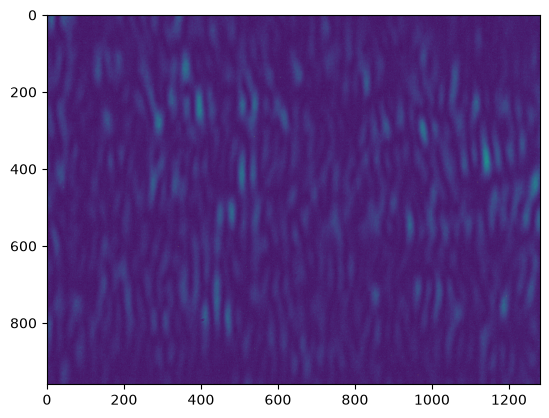

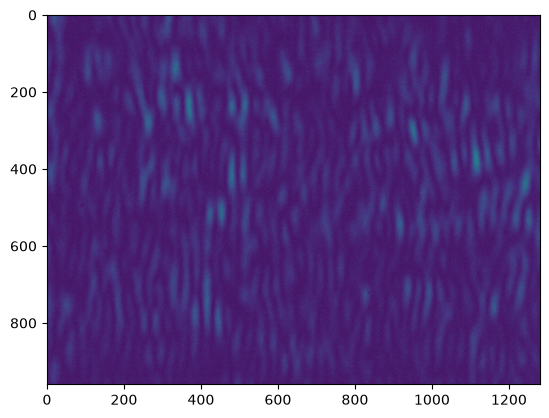

In [16]:
import matplotlib.pyplot as plt

with h5py.File(f"{FOLDER}data_HG_fix_amostra{AMOSTRA}_orientacao{ANGULO_AMOSTRA}.h5", "r") as file:
    img = file["HG_n3m0"]["images"][:]
    plt.figure()
    plt.imshow(img[0,0])
    plt.figure()
    plt.imshow(img[0,49])
    

In [14]:
close_camera(cam)
slm.close()